# Analysis 1 · Accuracy: How wrong are the forecasts?

This notebook compares the forecast error of physics-based and AI weather models: overall, by region, and after removing systematic biases.

**How to use this notebook:** All analyses are ready. Run all cells (or read the exported version).
Every figure has a number. When you check a claim, name the figure that supports or contradicts it.

Data: WeatherBench 2, January 2020, 64×32 grid (about 600 km), ERA5 as reference.
Dashed lines = physics-based models (HRES, IFS ENS). Solid lines = AI or hybrid models.

| Figure | What it shows |
|---|---|
| **1.1** | Forecast error over lead time, all models |
| **1.2** | Scorecard: error relative to HRES |
| **1.3** | Systematic bias of each model |
| **1.4** | Where the bias is: 2-m temperature maps |
| **1.5** | A fair re-match: errors after removing the bias |
| **1.6** | Regional differences |
| **1.7** | Where AI models beat HRES |
| **1.8** | One city over one month |

In [1]:
from wb2_helpers import *
CITY = 'Hannover'            # used for the city figures (see CITIES in wb2_helpers.py)
MAP_DATE = '2020-01-25T00'   # valid time for maps (between 2020-01-08 and 2020-02-07)
col = lambda m: COLORS[m.replace(' (mean)', '').replace(' (member)', '')]
available()

,HRES,GraphCast,Pangu,NeuralGCM,IFS ENS,GenCast,NeuralGCM ENS
2-m temperature (K),✅,✅,✅,—,✅,✅,—
10-m wind speed (m/s),✅,✅,✅,—,✅,✅,—
Z500 (m²/s²),✅,✅,✅,✅,✅,✅,✅


### Sanity check

In [2]:
# Sanity check: 3-day RMSE should be about 100 m²/s² for Z500 and about 1 K for 2-m temperature
rows = []
for m in DET:
    for v in ['geopotential', '2m_temperature']:
        fc, tr = det_forecast(m, v, 72)
        if fc is not None: rows.append({'model': m, 'variable': SHORT[v], 'RMSE day 3': rmse(fc, tr)})
for m, (n, md) in ENS.items():
    for v in ['geopotential', '2m_temperature']:
        fc, tr = ens_forecast(m, v, 72)
        if fc is not None: rows.append({'model': m + ' (mean)', 'variable': SHORT[v], 'RMSE day 3': rmse(fc.mean(md), tr)})
sanity = pd.DataFrame(rows)
sanity['plausible'] = np.where(sanity.variable == 'Z500', sanity['RMSE day 3'].between(10, 400),
                               sanity['RMSE day 3'].between(0.1, 4))
sanity.round(2)

,model,variable,RMSE day 3,plausible
0,HRES,Z500,121.81,True
1,HRES,T2m,1.01,True
2,GraphCast,Z500,109.25,True
3,GraphCast,T2m,0.61,True
4,Pangu,Z500,120.02,True
5,Pangu,T2m,0.71,True
6,NeuralGCM,Z500,100.43,True
7,IFS ENS (mean),Z500,119.17,True
8,IFS ENS (mean),T2m,0.94,True
9,GenCast (mean),Z500,109.60,True


### Figure 1.1 · Forecast error over lead time

*How to read:* RMSE, lower is better. Squares = ensemble means, circles = single forecasts. Missing lines mean the model does not provide this variable.

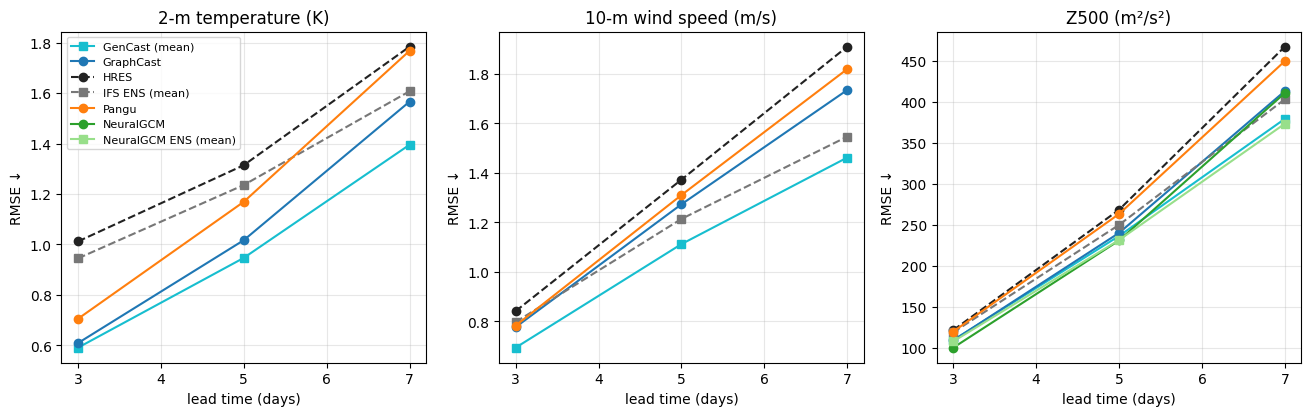

model                GenCast (mean)  GraphCast    HRES  IFS ENS (mean)  \
var            days                                                      
10m_wind_speed 3               0.69       0.78    0.84            0.80   
               5               1.11       1.27    1.37            1.21   
               7               1.46       1.73    1.91            1.55   
2m_temperature 3               0.59       0.61    1.01            0.94   
               5               0.95       1.02    1.31            1.24   
               7               1.40       1.57    1.78            1.61   
geopotential   3             109.70     109.25  121.81          119.17   
               5             236.48     240.21  268.42          250.00   
               7             379.17     412.96  467.08          402.97   

model                NeuralGCM  NeuralGCM ENS (mean)   Pangu  
var            days                                           
10m_wind_speed 3           NaN                   NaN    0.78  
               5           NaN                   NaN    1.31  
               7           NaN                   NaN    1.82  
2m_temperature 3           NaN                   NaN    0.71  
               5           NaN                   NaN    1.17  
               7           NaN                   NaN    1.77  
geopotential   3        100.43                108.03  120.02  
               5        231.00                231.56  263.31  
               7        410.61                373.23  449.48

In [3]:
rows = []
for var in VARS:
    for d, l in LEADS.items():
        for m in DET:
            fc, tr = det_forecast(m, var, l)
            if fc is not None:
                rows.append({'model': m, 'kind': 'single', 'var': var, 'days': d, 'rmse': rmse(fc, tr), 'bias': bias(fc, tr)})
        for m, (n, md) in ENS.items():
            fc, tr = ens_forecast(m, var, l, 50)
            if fc is not None:
                em = fc.mean(md)
                rows.append({'model': m + ' (mean)', 'kind': 'ensemble mean', 'var': var, 'days': d, 'rmse': rmse(em, tr), 'bias': bias(em, tr)})
acc = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for a, var in zip(axs, VARS):
    for m, s in acc[acc['var'] == var].groupby('model'):
        a.plot(s.days, s.rmse, marker='s' if 'mean' in m else 'o', ls=STYLE[m.replace(' (mean)', '')], color=col(m), label=m)
    a.set_title(VARS[var]); a.set_xlabel('lead time (days)'); a.set_ylabel('RMSE ↓'); a.grid(alpha=.3)
handles = {l: h for a in axs for h, l in zip(*a.get_legend_handles_labels())}  # NeuralGCM only has Z500
axs[0].legend(handles.values(), handles.keys(), fontsize=8)
save(fig, '1.1')
acc.pivot_table(index=['var', 'days'], columns='model', values='rmse').round(2)

### Figure 1.2 · Scorecard relative to HRES

*How to read:* Each cell: how much smaller (blue, negative) or larger (red, positive) the RMSE is compared with HRES. "–" = not available.

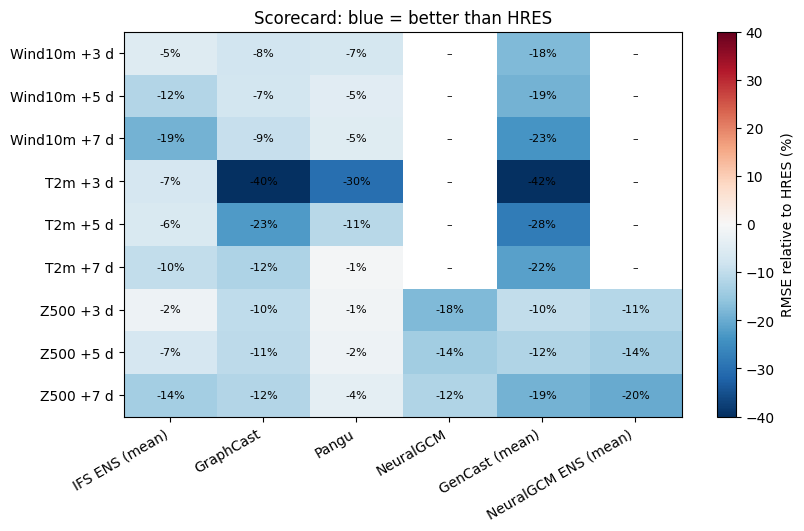

model                IFS ENS (mean)  GraphCast  Pangu  NeuralGCM  \
var            days                                                
10m_wind_speed 3               -5.2       -7.7   -6.9        NaN   
               5              -11.6       -7.3   -4.5        NaN   
               7              -19.0       -9.2   -4.7        NaN   
2m_temperature 3               -6.6      -39.8  -30.3        NaN   
               5               -6.0      -22.6  -11.0        NaN   
               7               -9.9      -12.2   -0.9        NaN   
geopotential   3               -2.2      -10.3   -1.5      -17.6   
               5               -6.9      -10.5   -1.9      -13.9   
               7              -13.7      -11.6   -3.8      -12.1   

model                GenCast (mean)  NeuralGCM ENS (mean)  
var            days                                        
10m_wind_speed 3              -17.5                   NaN  
               5              -19.0                   NaN  
               7              -23.5                   NaN  
2m_temperature 3              -41.6                   NaN  
               5              -28.0                   NaN  
               7              -21.8                   NaN  
geopotential   3               -9.9                 -11.3  
               5              -11.9                 -13.7  
               7              -18.8                 -20.1

In [4]:
piv = acc.pivot_table(index=['var', 'days'], columns='model', values='rmse')
rel = (piv.div(piv['HRES'], axis=0) - 1) * 100
rel = rel.drop(columns='HRES')
order = [c for c in ['IFS ENS (mean)', 'GraphCast', 'Pangu', 'NeuralGCM', 'GenCast (mean)', 'NeuralGCM ENS (mean)'] if c in rel.columns]
rel = rel[order]
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(rel.values, cmap='RdBu_r', vmin=-40, vmax=40, aspect='auto')
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=30, ha='right')
ax.set_yticks(range(len(rel))); ax.set_yticklabels([f'{SHORT[v]} +{d} d' for v, d in rel.index])
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        v = rel.values[i, j]
        ax.text(j, i, '–' if np.isnan(v) else f'{v:+.0f}%', ha='center', va='center', fontsize=8)
plt.colorbar(im, label='RMSE relative to HRES (%)'); ax.set_title('Scorecard: blue = better than HRES')
save(fig, '1.2')
rel.round(1)

### Figure 1.3 · Systematic bias

*How to read:* Mean error (forecast minus ERA5) averaged over the globe and the month. 0 = no systematic error. Negative = too cold / too low.

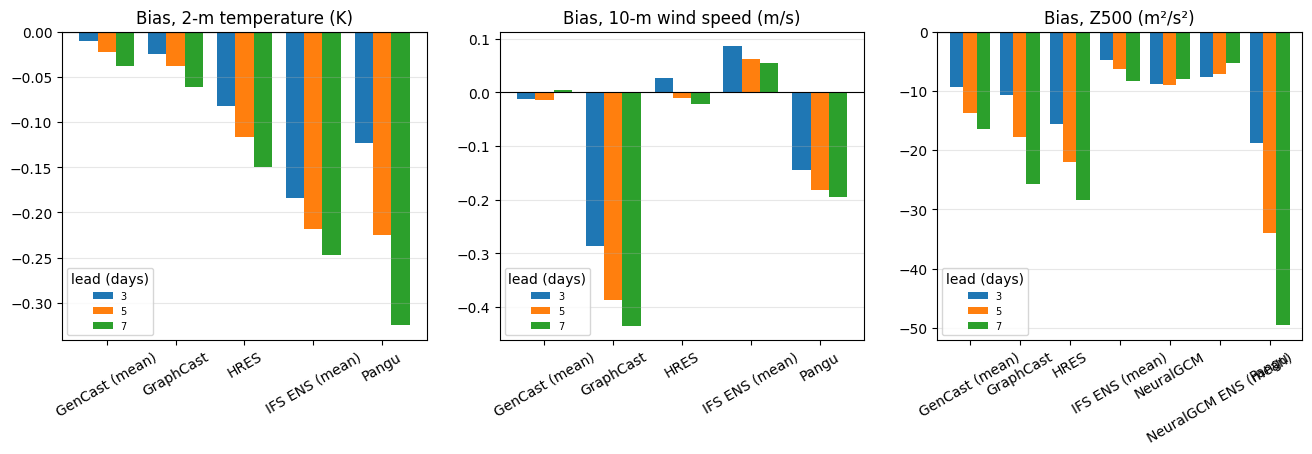

model                GenCast (mean)  GraphCast    HRES  IFS ENS (mean)  \
var            days                                                      
10m_wind_speed 3             -0.013     -0.287   0.026           0.088   
               5             -0.014     -0.388  -0.011           0.063   
               7              0.005     -0.435  -0.022           0.055   
2m_temperature 3             -0.011     -0.025  -0.082          -0.184   
               5             -0.023     -0.038  -0.116          -0.218   
               7             -0.038     -0.062  -0.150          -0.247   
geopotential   3             -9.324    -10.626 -15.661          -4.809   
               5            -13.791    -17.783 -21.931          -6.267   
               7            -16.449    -25.709 -28.366          -8.309   

model                NeuralGCM  NeuralGCM ENS (mean)   Pangu  
var            days                                           
10m_wind_speed 3           NaN                   NaN  -0.145  
               5           NaN                   NaN  -0.182  
               7           NaN                   NaN  -0.195  
2m_temperature 3           NaN                   NaN  -0.123  
               5           NaN                   NaN  -0.225  
               7           NaN                   NaN  -0.324  
geopotential   3        -8.890                -7.687 -18.860  
               5        -8.987                -7.235 -33.923  
               7        -7.980                -5.297 -49.479

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for a, var in zip(axs, VARS):
    s = acc[(acc['var'] == var)].pivot_table(index='model', columns='days', values='bias')
    s.plot.bar(ax=a, rot=30, width=0.8)
    a.axhline(0, color='k', lw=.8); a.set_title(f'Bias, {VARS[var]}'); a.set_xlabel(''); a.grid(alpha=.3, axis='y')
    a.legend(title='lead (days)', fontsize=7)
save(fig, '1.3')
acc.pivot_table(index=['var', 'days'], columns='model', values='bias').round(3)

### Figure 1.4 · Where the bias is

*How to read:* Mean error of the 3-day 2-m temperature forecast at each grid point. Blue = forecast too cold, red = too warm.

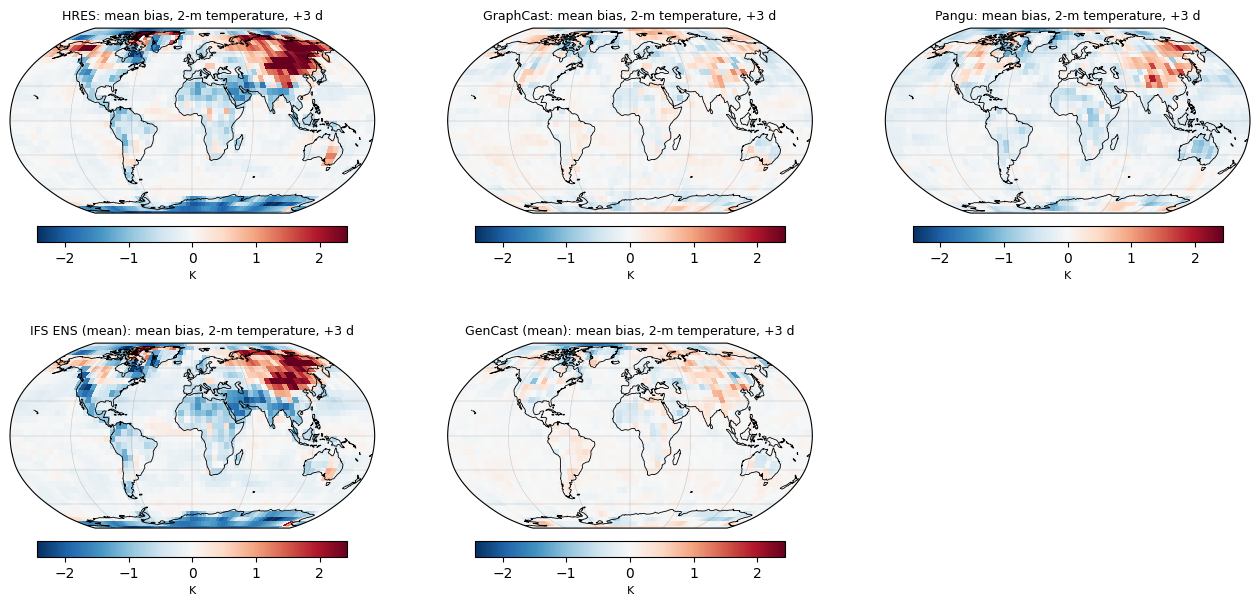

In [6]:
maps = {}
for m in ['HRES', 'GraphCast', 'Pangu']:
    fc, tr = det_forecast(m, '2m_temperature', LEADS[3]); maps[m] = (fc - tr).mean('time')
for m in ['IFS ENS', 'GenCast']:
    fc, tr = ens_forecast(m, '2m_temperature', LEADS[3], 50); maps[m + ' (mean)'] = (fc.mean(ENS[m][1]) - tr).mean('time')
v = float(max(abs(x).quantile(.98) for x in maps.values()))
fig, axs = map_subplots(2, 3, figsize=(16, 7.5))
for a, (m, b) in zip(axs.flat, maps.items()):
    plot_map(a, b, f'{m}: mean bias, 2-m temperature, +3 d', 'RdBu_r', -v, v, 'K')
axs.flat[-1].axis('off')
save(fig, '1.4')

### Figure 1.5 · A fair re-match

*How to read:* Each model's average error map is learned from forecasts valid before 20 January and removed from forecasts valid afterwards. Light bars = raw RMSE, dark bars = after bias removal, both on the second half of the month only.

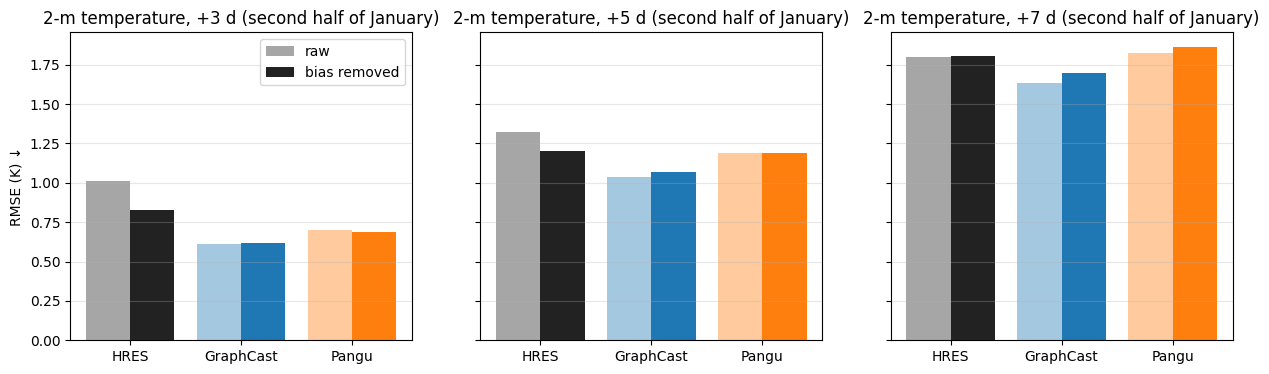

raw             bias removed              \
model GraphCast  HRES Pangu    GraphCast  HRES Pangu   
days                                                   
3          0.61  1.01  0.70         0.62  0.83  0.69   
5          1.03  1.32  1.19         1.07  1.20  1.19   
7          1.63  1.80  1.82         1.70  1.81  1.86   

      advantage GraphCast vs HRES (%)               
model                             raw bias removed  
days                                                
3                              -39.65       -25.06  
5                              -21.65       -10.86  
7                               -9.16        -5.95

In [7]:
SPLIT = np.datetime64('2020-01-20')
rows = []
for d, l in LEADS.items():
    for m in ['HRES', 'GraphCast', 'Pangu']:
        fc, tr = det_forecast(m, '2m_temperature', l)
        train, test = fc.time < SPLIT, fc.time >= SPLIT
        b = (fc - tr).isel(time=train).mean('time')
        f2, t2 = fc.isel(time=test), tr.isel(time=test)
        rows.append({'model': m, 'days': d, 'raw': rmse(f2, t2), 'bias removed': rmse(f2 - b, t2)})
fair = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, d in zip(axs, LEADS):
    s = fair[fair.days == d].set_index('model')
    x = np.arange(len(s))
    a.bar(x - .2, s.raw, .4, color=[col(m) for m in s.index], alpha=.4, label='raw')
    a.bar(x + .2, s['bias removed'], .4, color=[col(m) for m in s.index], label='bias removed')
    a.set_xticks(x); a.set_xticklabels(s.index); a.set_title(f'2-m temperature, +{d} d (second half of January)')
    a.grid(alpha=.3, axis='y')
axs[0].set_ylabel('RMSE (K) ↓'); axs[0].legend()
save(fig, '1.5')
out = fair.pivot(index='days', columns='model', values=['raw', 'bias removed'])
out[('advantage GraphCast vs HRES (%)', 'raw')] = (out[('raw', 'GraphCast')] / out[('raw', 'HRES')] - 1) * 100
out[('advantage GraphCast vs HRES (%)', 'bias removed')] = (out[('bias removed', 'GraphCast')] / out[('bias removed', 'HRES')] - 1) * 100
out.round(2)

### Figure 1.6 · Regional differences

*How to read:* RMSE relative to HRES in different regions at day 5. Negative = better than HRES.

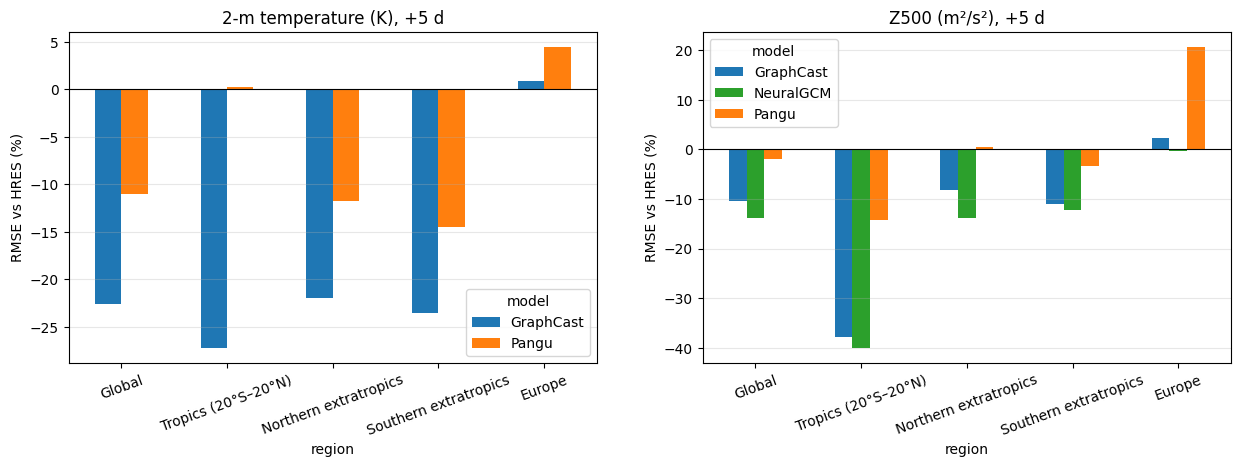

model                                 GraphCast    HRES  NeuralGCM   Pangu
var            region                                                     
2m_temperature Europe                      1.37    1.36        NaN    1.42
               Global                      1.02    1.31        NaN    1.17
               Northern extratropics       1.62    2.07        NaN    1.83
               Southern extratropics       0.69    0.91        NaN    0.78
               Tropics (20°S–20°N)         0.45    0.61        NaN    0.61
geopotential   Europe                    383.37  374.99     373.49  452.29
               Global                    240.21  268.42     231.00  263.31
               Northern extratropics     312.14  340.29     293.01  341.72
               Southern extratropics     293.23  329.48     289.40  318.10
               Tropics (20°S–20°N)        53.27   85.57      51.31   73.29

In [8]:
rows = []
for var in ['2m_temperature', 'geopotential']:
    for m in ['HRES', 'GraphCast', 'Pangu', 'NeuralGCM']:
        fc, tr = det_forecast(m, var, LEADS[5])
        if fc is None: continue
        for reg in REGIONS:
            rows.append({'var': var, 'model': m, 'region': reg, 'rmse': regional_rmse(fc, tr, reg)})
reg = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.3))
for a, var in zip(axs, ['2m_temperature', 'geopotential']):
    p = reg[reg['var'] == var].pivot(index='region', columns='model', values='rmse')
    r = (p.div(p['HRES'], axis=0) - 1) * 100
    r = r.drop(columns='HRES').loc[list(REGIONS)]
    r.plot.bar(ax=a, rot=20, color=[col(m) for m in r.columns])
    a.axhline(0, color='k', lw=.8); a.set_ylabel('RMSE vs HRES (%)'); a.set_title(f'{VARS[var]}, +5 d'); a.grid(alpha=.3, axis='y')
save(fig, '1.6')
reg.pivot_table(index=['var', 'region'], columns='model', values='rmse').round(2)

### Figure 1.7 · Where AI models beat HRES

*How to read:* Difference in RMSE at each grid point (model minus HRES), 2-m temperature at day 5. Blue = the AI model is better there.

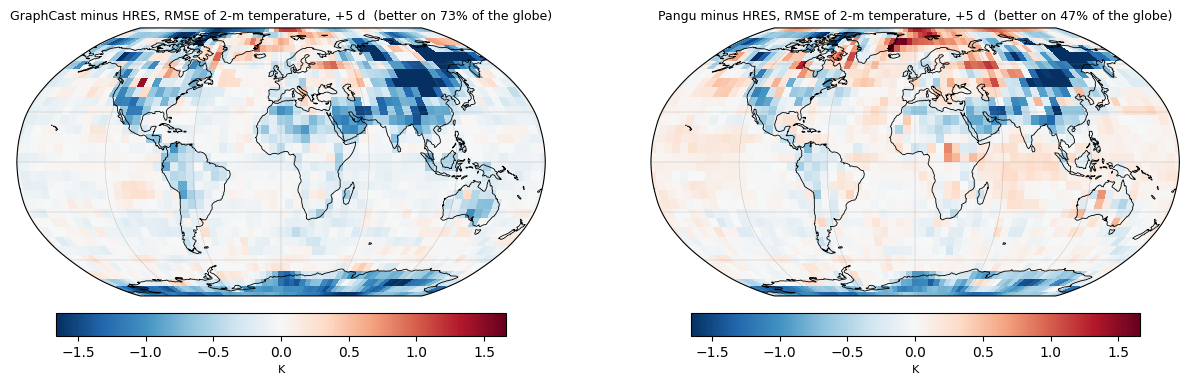

In [9]:
h, ht = det_forecast('HRES', '2m_temperature', LEADS[5])
h_map = np.sqrt(((h - ht) ** 2).mean('time'))
diffs, share = {}, {}
for m in ['GraphCast', 'Pangu']:
    fc, tr = det_forecast(m, '2m_temperature', LEADS[5])
    diffs[m] = np.sqrt(((fc - tr) ** 2).mean('time')) - h_map
    share[m] = float((diffs[m] < 0).weighted(np.cos(np.deg2rad(diffs[m].latitude))).mean())
v = float(max(abs(x).quantile(.98) for x in diffs.values()))
fig, axs = map_subplots(1, 2, figsize=(15, 4.5))
for a, (m, dmap) in zip(axs, diffs.items()):
    plot_map(a, dmap, f'{m} minus HRES, RMSE of 2-m temperature, +5 d  (better on {share[m]:.0%} of the globe)', 'RdBu_r', -v, v, 'K')
save(fig, '1.7')

### Figure 1.8 · One city over one month

*How to read:* Five-day forecasts of 2-m temperature for the grid box containing the city. Black = what happened. The legend shows each model's mean absolute error.

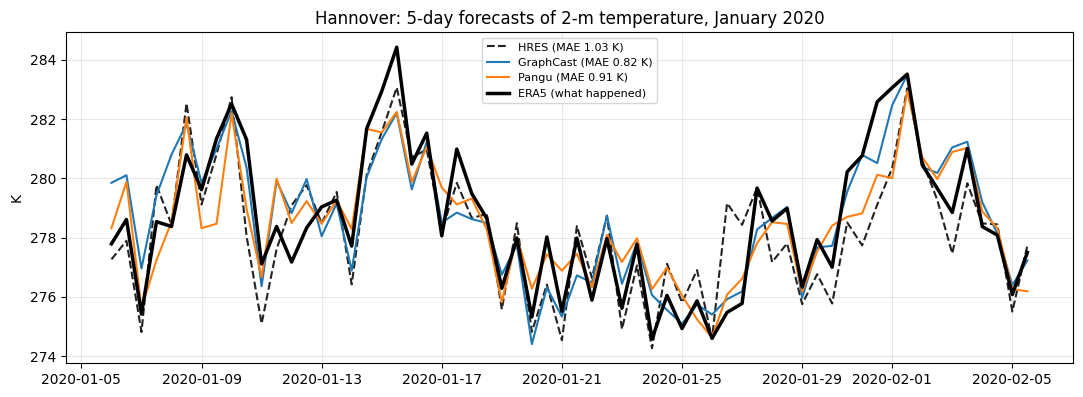

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.3))
tr_city = None
for m in DET:
    fc, tr = det_forecast(m, '2m_temperature', LEADS[5])
    if fc is None: continue
    p, pt = point(fc, CITY), point(tr, CITY); tr_city = pt
    ax.plot(p.time, p, ls=STYLE[m], color=COLORS[m], lw=1.5, label=f'{m} (MAE {float(abs(p - pt).mean()):.2f} K)')
ax.plot(tr_city.time, tr_city, 'k', lw=2.5, label='ERA5 (what happened)')
ax.set_title(f'{CITY}: 5-day forecasts of 2-m temperature, January 2020'); ax.set_ylabel('K'); ax.grid(alpha=.3); ax.legend(fontsize=8)
save(fig, '1.8')